In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu130
Device: cuda


In [2]:
# Test-train split
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

classes = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", classes)

100%|██████████| 170M/170M [38:31<00:00, 73.8kB/s]


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
image, label = test_dataset[0]
raw_image = test_dataset.data[0]

print("Raw image:")
print("  shape:", raw_image.shape)
print("  dtype:", raw_image.dtype)
print("  range:", raw_image.min(), raw_image.max())

print("\nModel input:")
print("  shape:", image.shape)
print("  dtype:", image.dtype)
print("  range:", image.min().item(), image.max().item())

print("\nLabel:", label, "→", classes[label])

Raw image:
  shape: (32, 32, 3)
  dtype: uint8
  range: 13 255

Model input:
  shape: torch.Size([3, 32, 32])
  dtype: torch.float32
  range: 0.05098039284348488 1.0

Label: 3 → cat


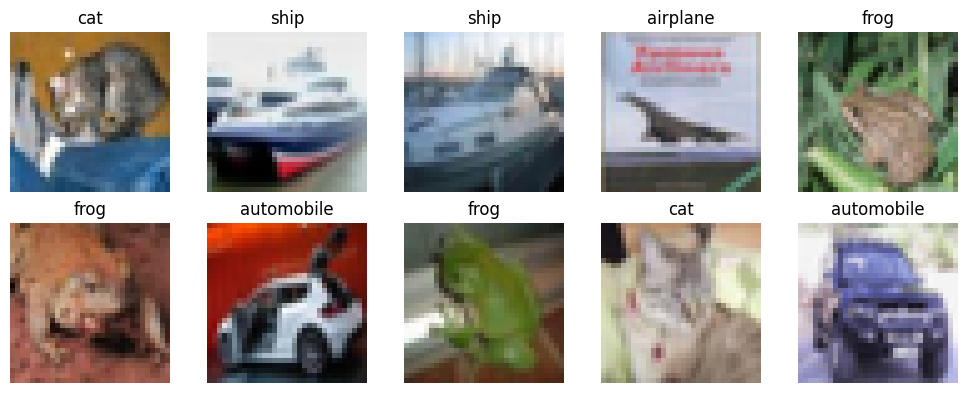

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for index, ax in enumerate(axes.flat):
    image, label = test_dataset[index]
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

### We are taking 128 images per batch

In [5]:
# Inspect one batch
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
)

images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

assert images.shape == (128, 3, 32, 32)
assert labels.shape == (128,)
assert 0 <= images.min().item() <= images.max().item() <= 1

Images: torch.Size([128, 3, 32, 32])
Labels: torch.Size([128])


In [6]:
img25=test_dataset.data[25]
img25[10,15,:]

array([142, 204, 121], dtype=uint8)

## Using a Pretrained CNN to implement the attack

In [7]:
import numpy as np
import torch


class CNNPredictor:
    def __init__(self, model, mean, std, device="cuda", batch_size=64):
        self.device = torch.device(device)
        self.model = model.to(self.device).eval()
        self.batch_size = batch_size

        self.mean = torch.tensor(
            mean, dtype=torch.float32, device=self.device
        ).view(1, 3, 1, 1)

        self.std = torch.tensor(
            std, dtype=torch.float32, device=self.device
        ).view(1, 3, 1, 1)

    @torch.inference_mode()
    def __call__(self, images):

        #Input: (N, H, W, 3)

        outputs = []

        for start in range(0, len(images), self.batch_size):
            batch = np.ascontiguousarray(
                images[start:start + self.batch_size]
            )

            x = torch.from_numpy(batch).to(self.device)
            x = x.permute(0, 3, 1, 2).float() / 255.0
            x = (x - self.mean) / self.std

            logits = self.model(x)
            probabilities = logits.softmax(dim=1)
            # Output: probabilities
            outputs.append(probabilities.cpu().numpy())

        return np.concatenate(outputs, axis=0)

## Loading a CIFAR-trained Resnet-18 from huggingface

In [8]:
%pip install -q timm

Note: you may need to restart the kernel to use updated packages.


In [9]:
import timm
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Match this checkpoint's CIFAR-10 architecture.
pretrained_model = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=10,
)

pretrained_model.conv1 = nn.Conv2d(
    3, 64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False,
)

pretrained_model.maxpool = nn.Identity()

checkpoint_url = (
    "https://huggingface.co/edadaltocg/resnet18_cifar10/"
    "resolve/main/pytorch_model.bin"
)

state_dict = torch.hub.load_state_dict_from_url(
    checkpoint_url,
    map_location="cpu",
    file_name="edadaltocg_resnet18_cifar10.pth",
    weights_only=True,
)

pretrained_model.load_state_dict(state_dict, strict=True)
pretrained_model = pretrained_model.to(device).eval()
pretrained_model.requires_grad_(False)

# Normalization specifically for this checkpoint.
checkpoint_mean = [0.4914, 0.4822, 0.4465]
checkpoint_std = [0.2023, 0.1994, 0.2010]

predict = CNNPredictor(
    model=pretrained_model,
    mean=checkpoint_mean,
    std=checkpoint_std,
    device=device,
    batch_size=128,
)

class_names = test_dataset.classes

print("CIFAR-10 ResNet-18 loaded.")

Downloading: "https://huggingface.co/edadaltocg/resnet18_cifar10/resolve/main/pytorch_model.bin" to /root/.cache/torch/hub/checkpoints/edadaltocg_resnet18_cifar10.pth


100%|██████████| 42.7M/42.7M [00:00<00:00, 57.0MB/s]


CIFAR-10 ResNet-18 loaded.


Before the pixel attack:-

- Create a separate copy of the original for each candidate
- Clip and rounds candidates to valid coordinates and RGB values.

We send this batch of images for the pixel attack

In [10]:
def apply_candidates(image, candidates):
    height, width, _ = image.shape

    upper = np.array([
        height - 1, width - 1, 255, 255, 255
    ])

    decoded = np.rint(
        np.clip(candidates, 0, upper)
    ).astype(np.int64)

    images = np.repeat(
        image[None, ...], len(decoded), axis=0
    )

    indices = np.arange(len(decoded))

    images[
        indices,
        decoded[:, 0],
        decoded[:, 1],
        :
    ] = decoded[:, 2:].astype(np.uint8)

    return images

## Implementing One Pixel Attack

- image:
    uint8 RGB image at the model's input resolution.
- true_label:
    Ground-truth index in the model's class mapping.
- predict:
    Callable: uint8 images (N,H,W,3) -> probabilities (N,C).
- target_label:
    None for untargeted; otherwise the desired class index.
- stop_rule:
    "paper"   -> target probability > .90, or true probability < .05
    "success" -> stop when an actual adversarial candidate is found
    "budget"  -> use all generations

#### Implemented in 4 stages:-

- **Initialization:** Generate random candidates specifying a pixel location and replacement RGB values.
- **Evaluation:** Query the CNN to score how well each candidate achieves the attack objective.
- **Mutation:** Combine three distinct candidates to generate a new candidate using \(v=a+0.5(b-c)\).
- **Selection:** Keep each new candidate if it improves on its corresponding parent; otherwise, retain the parent.

In [11]:
def one_pixel_attack(
    image,
    true_label,
    predict,
    target_label=None,
    population_size=400,
    generations=100,
    mutation_factor=0.5,
    stop_rule="paper",
    seed=42,
):

    if (
        image.dtype != np.uint8
        or image.ndim != 3
        or image.shape[2] != 3
    ):
        raise ValueError("image must be a uint8 RGB array.")

    if population_size < 4:
        raise ValueError("population_size must be at least 4.")

    if generations < 0 or mutation_factor <= 0:
        raise ValueError("Invalid generation count or mutation factor.")

    if stop_rule not in {"paper", "success", "budget"}:
        raise ValueError("Unknown stop_rule.")

    rng = np.random.default_rng(seed)
    height, width, _ = image.shape

    upper = np.array(
        [height - 1, width - 1, 255, 255, 255],
        dtype=float,
    )

    # Check the original image before attempting an attack.
    clean_probabilities = np.asarray(predict(image[None]))[0]
    number_of_classes = len(clean_probabilities)

    if not 0 <= true_label < number_of_classes:
        raise ValueError("true_label is outside the model's class range.")

    if target_label is not None:
        if not 0 <= target_label < number_of_classes:
            raise ValueError("target_label is outside the class range.")
        if target_label == true_label:
            raise ValueError("Target must differ from the true label.")

    clean_prediction = int(clean_probabilities.argmax())

    if clean_prediction != true_label:
        raise ValueError(
            "The original image is already misclassified. "
            "Exclude it from attack-success evaluation."
        )

    #1. INITIALIZATION
    population = np.empty((population_size, 5), dtype=float)

    population[:, 0] = rng.uniform(
        0, height - 1, population_size
    )
    population[:, 1] = rng.uniform(
        0, width - 1, population_size
    )
    # Initially we use a Guassian Dist. to pick the initial RGB values
    population[:, 2:] = rng.normal(
        loc=128, scale=127, size=(population_size, 3)
    )
    # clip RGB values b/w 0-255
    population = np.clip(population, 0, upper)

    attack_queries = 0
    best_seen = None
    best_success = None
    history = []

    # 2. EVALUATION
    def evaluate(candidates):
        nonlocal attack_queries, best_seen, best_success

        modified = apply_candidates(image, candidates)
        # Query the CNN on modified img
        probabilities = np.asarray(predict(modified))

        if (
            probabilities.shape != (len(candidates), number_of_classes)
            or not np.isfinite(probabilities).all()
            or np.any(probabilities < 0)
            or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)
        ):
            raise ValueError("predict must return valid class probabilities.")

        # One evaluated image = one query, regardless of batching.
        attack_queries += len(candidates)

        predictions = probabilities.argmax(axis=1)

        if target_label is None:
            # Untargeted: minimize the true-class probability
            fitness = probabilities[:, true_label]
            successful = predictions != true_label
            threshold_reached = probabilities[:, true_label] < 0.05
        else:
            # Targeted: minimize the negative target probability
            fitness = -probabilities[:, target_label]
            successful = predictions == target_label
            threshold_reached = probabilities[:, target_label] > 0.90

        # Preserve successful examples even if a different candidate
        # later has better fitness but does not satisfy the class criterion.
        for i in range(len(candidates)):
            record = {
                "fitness": float(fitness[i]),
                "candidate": candidates[i].copy(),
                "probabilities": probabilities[i].copy(),
            }

            if best_seen is None or record["fitness"] < best_seen["fitness"]:
                best_seen = record

            if successful[i]:
                if (
                    best_success is None
                    or record["fitness"] < best_success["fitness"]
                ):
                    best_success = record
        # stopping rule
        if stop_rule == "success":
            stop = bool(successful.any())
        elif stop_rule == "paper":
            stop = bool(threshold_reached.any())
        else:
            stop = False

        return fitness, stop

    fitness, should_stop = evaluate(population)
    history.append(best_seen["fitness"])
    completed_generations = 0

    for generation in range(generations):
        if should_stop:
            break

        # 3. DIFFERENTIAL MUTATION
        trials = np.empty_like(population)

        for i in range(population_size):
            # Three distinct donors, also excluding the current parent.
            possible_donors = np.delete(
                np.arange(population_size), i
            )
            a, b, c = rng.choice(
                possible_donors, size=3, replace=False
            )
            # Mutation
            trials[i] = (
                population[a]
                + mutation_factor * (population[b] - population[c])
            )

        trials = np.clip(trials, 0, upper)

        # No crossover: evaluate the entire mutant vector.
        trial_fitness, should_stop = evaluate(trials)

        #  4. PARENT–CHILD SELECTION
        improved = trial_fitness < fitness

        population[improved] = trials[improved]
        fitness[improved] = trial_fitness[improved]

        completed_generations = generation + 1
        history.append(best_seen["fitness"])

    chosen = best_success if best_success is not None else best_seen

    candidate = np.rint(
        np.clip(chosen["candidate"], 0, upper)
    ).astype(int)
    # creates the final attacked image
    adversarial = apply_candidates(image, candidate[None])[0]

    changed_pixels = int(
        np.any(adversarial != image, axis=2).sum()
    )
    assert changed_pixels <= 1

    row, column = candidate[:2]
    difference = np.abs(
        adversarial.astype(float) - image.astype(float)
    )

    return {
        "success": best_success is not None,
        "adversarial": adversarial,
        "candidate": candidate,
        "clean_prediction": clean_prediction,
        "adversarial_prediction": int(
            chosen["probabilities"].argmax()
        ),
        "clean_probabilities": clean_probabilities,
        "adversarial_probabilities": chosen["probabilities"],
        "attack_queries": attack_queries,
        "total_queries": attack_queries + 1,
        "generations": completed_generations,
        "changed_pixels": changed_pixels,
        "pixel_mae": float(difference[row, column].mean()),
        "fitness_history": history,
    }

## Use the One pixel attack on a pretrained CNN

- pretrained_model: loaded CNN
- checkpoint_mean: three normalization means
- checkpoint_std: three normalization standard deviations

In [12]:
predict = CNNPredictor(
    model=pretrained_model,
    mean=checkpoint_mean,
    std=checkpoint_std,
    device=device,
)

## Untargeted Attack - No target label

#### 1.Before attacking

In [13]:
test_images = test_dataset.data
test_labels = np.asarray(test_dataset.targets)

clean_probabilities = predict(test_images)
assert clean_probabilities.shape == (len(test_images), 10)

clean_predictions = clean_probabilities.argmax(axis=1)
clean_correct = clean_predictions == test_labels

print(f"Clean test accuracy: {clean_correct.mean():.2%}")

Clean test accuracy: 94.98%


#### 2.Attack one image

In [14]:
correct_indices = np.flatnonzero(clean_correct)

if len(correct_indices) == 0:
    raise RuntimeError("No correct predictions: check the model loading.")

rng = np.random.default_rng(SEED)
image_index = int(rng.choice(correct_indices))

image = test_images[image_index].copy()
true_label = int(test_labels[image_index])

result = one_pixel_attack(
    image=image,
    true_label=true_label,
    predict=predict,
    population_size=400,
    generations=100,
    stop_rule="success",
    seed=SEED,
)

print("CIFAR-10 image index:", image_index)
print("Actual class:", class_names[true_label])
print("Before:", class_names[result["clean_prediction"]])
print("After:", class_names[result["adversarial_prediction"]])
print("Attack success:", result["success"])
print("Changed pixels:", result["changed_pixels"])
print("Attack queries:", result["attack_queries"])

print(
    "True-class probability:",
    f"{result['clean_probabilities'][true_label]:.3f}",
    "→",
    f"{result['adversarial_probabilities'][true_label]:.3f}",
)

CIFAR-10 image index: 888
Actual class: airplane
Before: airplane
After: ship
Attack success: True
Changed pixels: 1
Attack queries: 400
True-class probability: 0.958 → 0.390


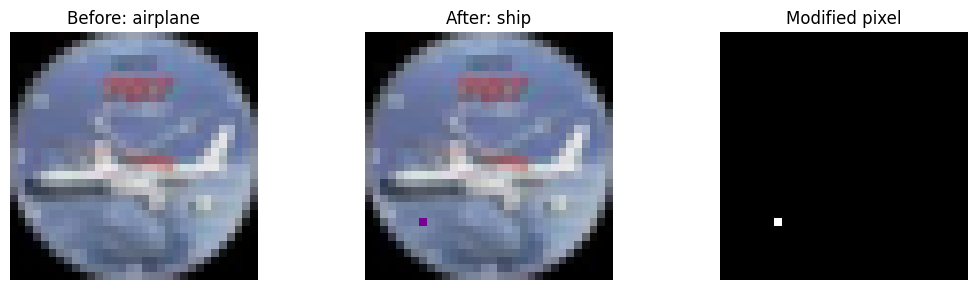

In [15]:
adversarial = result["adversarial"]
changed_mask = np.any(image != adversarial, axis=2)

assert changed_mask.sum() <= 1

fig, axes = plt.subplots(1, 3, figsize=(11, 3))

axes[0].imshow(image)
axes[0].set_title(
    f"Before: {class_names[result['clean_prediction']]}"
)

axes[1].imshow(adversarial)
axes[1].set_title(
    f"After: {class_names[result['adversarial_prediction']]}"
)

axes[2].imshow(changed_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Modified pixel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3.Run the attack on 100 random images

In [16]:
N = 100

rng = np.random.default_rng(SEED)
subset_indices = rng.choice(
    len(test_images), size=N, replace=False
)

before_predictions = clean_predictions[subset_indices].copy()
after_predictions = before_predictions.copy()
subset_labels = test_labels[subset_indices]

attack_records = []

for position, index in enumerate(subset_indices):
    index = int(index)
    label = int(test_labels[index])

    # An existing classification error isn't an attack success.
    if clean_predictions[index] != label:
        continue

    output = one_pixel_attack(
        image=test_images[index].copy(),
        true_label=label,
        predict=predict,
        population_size=400,
        generations=100,
        stop_rule="success",
        seed=SEED + index,
    )

    assert output["changed_pixels"] <= 1

    after_predictions[position] = output["adversarial_prediction"]

    attack_records.append({
        "index": index,
        "success": bool(output["success"]),
        "queries": output["attack_queries"],
        "pixel_mae": output["pixel_mae"],
    })

    print(
        f"Image {index}: "
        f"{class_names[label]} → "
        f"{class_names[output['adversarial_prediction']]} | "
        f"success={output['success']}"
    )

Image 4363: truck → truck | success=False
Image 6684: ship → ship | success=False
Image 4645: deer → deer | success=False
Image 4473: deer → deer | success=False
Image 7744: deer → deer | success=False
Image 1536: dog → cat | success=True
Image 3247: cat → cat | success=False
Image 1642: dog → cat | success=True
Image 7113: truck → automobile | success=True
Image 1811: automobile → ship | success=True
Image 4955: bird → airplane | success=True
Image 4289: horse → horse | success=False
Image 8168: frog → cat | success=True
Image 3692: deer → deer | success=False
Image 6909: deer → deer | success=False
Image 1996: cat → frog | success=True
Image 8821: horse → horse | success=False
Image 9640: dog → dog | success=False
Image 2256: deer → deer | success=False
Image 9189: deer → deer | success=False
Image 8884: airplane → airplane | success=False
Image 1270: automobile → automobile | success=False
Image 1604: automobile → automobile | success=False
Image 8329: ship → ship | success=False
Im

In [17]:
before_accuracy = np.mean(before_predictions == subset_labels)
after_accuracy = np.mean(after_predictions == subset_labels)

attempted = len(attack_records)
successful = sum(row["success"] for row in attack_records)

print(f"\nComparison on the SAME {N} CIFAR-10 images")
print(f"Accuracy before attack: {before_accuracy:.2%}")
print(f"Accuracy after attack:  {after_accuracy:.2%}")
print(f"Attacks attempted:      {attempted}")
print(f"Successful attacks:    {successful}")

if attempted:
    print(f"Attack success rate:    {successful / attempted:.2%}")
    print(
        "Mean attack queries:   "
        f"{np.mean([r['queries'] for r in attack_records]):.1f}"
    )
else:
    print("Attack success rate: undefined—no eligible images.")


Comparison on the SAME 100 CIFAR-10 images
Accuracy before attack: 96.00%
Accuracy after attack:  61.00%
Attacks attempted:      96
Successful attacks:    35
Attack success rate:    36.46%
Mean attack queries:   26425.0


## Attack on Pretrained VGC-16

In [18]:
import timm
import torch
import torch.nn as nn

vgg_model = timm.create_model(
    "vgg16_bn",
    pretrained=False,
)

# Match this checkpoint's CIFAR-10 classifier.
vgg_model.pre_logits = nn.Identity()
vgg_model.head.fc = nn.Linear(512, 10)

state_dict = torch.hub.load_state_dict_from_url(
    "https://huggingface.co/edadaltocg/vgg16_bn_cifar10/"
    "resolve/main/pytorch_model.bin",
    map_location="cpu",
    file_name="edadaltocg_vgg16_bn_cifar10.pth",
    weights_only=True,
)

vgg_model.load_state_dict(state_dict, strict=True)
vgg_model = vgg_model.to(device).eval()
vgg_model.requires_grad_(False)

predict_vgg = CNNPredictor(
    model=vgg_model,
    mean=[0.4914, 0.4822, 0.4465],
    std=[0.2023, 0.1994, 0.2010],
    device=device,
    batch_size=64,
)

Downloading: "https://huggingface.co/edadaltocg/vgg16_bn_cifar10/resolve/main/pytorch_model.bin" to /root/.cache/torch/hub/checkpoints/edadaltocg_vgg16_bn_cifar10.pth


100%|██████████| 56.2M/56.2M [00:01<00:00, 51.1MB/s]


In [19]:
import json
from pathlib import Path

# Evaluate VGG on the original test images.
vgg_clean_probs = predict_vgg(test_images)
vgg_clean_predictions = vgg_clean_probs.argmax(axis=1)

labels = np.asarray(test_labels)
vgg_correct = vgg_clean_predictions == labels

N = 500
rng = np.random.default_rng(SEED)
selected_indices = rng.choice(len(test_images), size=N, replace=False)

# Initially, after-attack predictions equal original predictions.
after_predictions = vgg_clean_predictions.copy()

# Use a new file to avoid mixing different experiments.
results_path = Path("vgg_one_pixel_10k.jsonl")

attempted = 0
successful = 0
total_queries = 0

with results_path.open("x") as file:
    for position, index in enumerate(selected_indices, start=1):
        index = int(index)
        true_label = int(labels[index])
        before = int(vgg_clean_predictions[index])

        record = {
            "index": index,
            "true_label": true_label,
            "before": before,
            "after": before,
            "attacked": False,
            "success": False,
            "queries": 0,
        }

        # Already incorrect images remain unchanged.
        if vgg_correct[index]:
            result = one_pixel_attack(
                image=test_images[index].copy(),
                true_label=true_label,
                predict=predict_vgg,
                population_size=400,
                generations=100,
                stop_rule="success",
                seed=SEED + index,
            )

            assert result["changed_pixels"] <= 1

            after_predictions[index] = result["adversarial_prediction"]

            attempted += 1
            successful += int(result["success"])
            total_queries += result["attack_queries"]

            record.update({
                "after": int(result["adversarial_prediction"]),
                "attacked": True,
                "success": bool(result["success"]),
                "queries": int(result["attack_queries"]),
                "candidate": result["candidate"].tolist(),
                "changed_pixels": int(result["changed_pixels"]),
                "pixel_mae": float(result["pixel_mae"]),
            })

        file.write(json.dumps(record) + "\n")
        file.flush()

        if position % 10 == 0 or position == N:
            print(
                f"Processed {position}/{N} | "
                f"Attacked: {attempted} | "
                f"Successful: {successful}",
                flush=True,
            )

# Compare predictions on exactly the same selected images.
before_accuracy = np.mean(
    vgg_clean_predictions[selected_indices] == labels[selected_indices]
)

after_accuracy = np.mean(
    after_predictions[selected_indices] == labels[selected_indices]
)

print("\nVGG-16: before vs after One Pixel Attack")
print(f"Images evaluated:       {N}")
print(f"Accuracy before attack: {before_accuracy:.2%}")
print(f"Accuracy after attack:  {after_accuracy:.2%}")
print(f"Images attacked:        {attempted}")
print(f"Successful attacks:     {successful}")

if attempted:
    print(f"Attack success rate:    {successful / attempted:.2%}")
    print(f"Mean attack queries:    {total_queries / attempted:.1f}")

print(f"Results saved to: {results_path}")

Processed 10/500 | Attacked: 10 | Successful: 5
Processed 20/500 | Attacked: 20 | Successful: 11
Processed 30/500 | Attacked: 29 | Successful: 17
Processed 40/500 | Attacked: 39 | Successful: 20
Processed 50/500 | Attacked: 48 | Successful: 23
Processed 60/500 | Attacked: 58 | Successful: 30
Processed 70/500 | Attacked: 67 | Successful: 34
Processed 80/500 | Attacked: 76 | Successful: 38
Processed 90/500 | Attacked: 85 | Successful: 43
Processed 100/500 | Attacked: 94 | Successful: 49
Processed 110/500 | Attacked: 102 | Successful: 51
Processed 120/500 | Attacked: 112 | Successful: 57
Processed 130/500 | Attacked: 121 | Successful: 61
Processed 140/500 | Attacked: 130 | Successful: 66
Processed 150/500 | Attacked: 140 | Successful: 71
Processed 160/500 | Attacked: 150 | Successful: 73
Processed 170/500 | Attacked: 160 | Successful: 78
Processed 180/500 | Attacked: 169 | Successful: 83
Processed 190/500 | Attacked: 178 | Successful: 87
Processed 200/500 | Attacked: 186 | Successful: 93
